# Comparative RAG Pipeline: Lexical vs. Dense Retrieval over a Textbook

A complete Retrieval-Augmented Generation (RAG) system that answers questions about a long PDF, built so that the **only thing that changes between runs is the retriever**. Four retrieval methods are compared on identical chunks, identical prompts and the same local LLM.

| Retriever | Representation |
|---|---|
| TF-IDF | sparse, lexical |
| Word2Vec (trained on the book) | dense, averaged word vectors |
| BERT (`bert-base-uncased`) | dense, mean-pooled contextual embeddings, no retrieval fine-tuning |
| all-mpnet-base-v2 | dense, sentence-transformer trained for semantic search |

**Pipeline:** PDF parsing (PyMuPDF) -> cleaning and boilerplate filtering -> sentence-based chunking -> embeddings -> cosine-similarity retrieval -> token-budgeted prompt -> answer generation with Flan-T5.

**Evaluation** (section 7) goes beyond reading a few answers by hand:

* *Retrieval*: Hit@5, Precision@5 and MRR@10 against a small question set with rule-based relevance labels.
* *Generation*: grounding in the retrieved context, expected-term coverage and refusal rate.

Corpus: *Psychology 2e*, OpenStax (CC BY 4.0).

> Run the notebook top to bottom. A GPU runtime (for example Colab, `Runtime > Change runtime type > T4 GPU`) makes embedding and generation much faster, but a CPU also works.

## 1. Setup

In [1]:
%pip install -q pymupdf nltk scikit-learn gensim transformers sentence-transformers tqdm requests pandas matplotlib

In [2]:
import os
import re
import warnings
from pathlib import Path
from typing import Callable, Dict, List

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # keep the saved notebook output readable
os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore", category=FutureWarning)

try:
    import pymupdf as fitz   # current PyMuPDF import name
except ImportError:
    import fitz              # older releases
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import requests
import torch
from gensim.models import Word2Vec
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from tqdm.auto import tqdm
from transformers import AutoModel, AutoModelForSeq2SeqLM, AutoTokenizer

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
STOPWORDS = set(stopwords.words("english"))

device: cuda


## 2. Configuration

All tunable choices live here, so every experiment is reproducible from one cell.

In [3]:
PDF_URL = "https://assets.openstax.org/oscms-prodcms/media/documents/Psychology2e_WEB.pdf"
PDF_PATH = Path("psychology-2e.pdf")

MAX_PAGES = None          # set to a small number (e.g. 80) for a quick smoke test
CHUNK_SENTENCES = 6       # sentences per chunk
MIN_CHUNK_WORDS = 30
MIN_ALPHA_RATIO = 0.6     # chunks with fewer letters than this share are treated as noise

TOP_K = 3                 # passages given to the LLM
LLM_NAME = "google/flan-t5-large"
LLM_MAX_INPUT_TOKENS = 512
MAX_NEW_TOKENS = 128

## 3. Get the PDF

In [4]:
if not PDF_PATH.exists():
    print("Downloading PDF ...")
    response = requests.get(PDF_URL, timeout=120)
    response.raise_for_status()
    PDF_PATH.write_bytes(response.content)
print(f"{PDF_PATH} ({PDF_PATH.stat().st_size / 1e6:.1f} MB)")

psychology-2e.pdf (57.7 MB)


## 4. Parse, clean and chunk

* Page text is extracted with PyMuPDF and whitespace is normalised.
* Pages are split into sentences and grouped into chunks of `CHUNK_SENTENCES` sentences. Chunks never cross page boundaries, so every chunk keeps an exact page reference.
* **Noise filter**: a textbook contains text that *looks* like prose but is not content: copyright pages, tables of contents, and the end-of-chapter review questions and multiple-choice options. Dense retrievers are especially easy to fool with them, because a list of questions about "depression" is semantically close to the query "symptoms of depression". The filter drops chunks that are too short, have too few letters, contain licence/front-matter text, look like a table of contents, or consist of questions and answer options.

In [5]:
def clean_text(text: str) -> str:
    return re.sub(r"\s+", " ", text).strip()


def extract_pages(pdf_path: Path, max_pages=None) -> List[Dict]:
    doc = fitz.open(str(pdf_path))
    total = doc.page_count if max_pages is None else min(max_pages, doc.page_count)
    pages = []
    for page_number in tqdm(range(total), desc="Parsing PDF"):
        text = clean_text(doc.load_page(page_number).get_text())
        if text:
            pages.append({"page_number": page_number + 1, "text": text})
    doc.close()
    return pages


FRONT_MATTER = re.compile(r"OpenStax|Rice University|Creative Commons|ISBN|All rights reserved|Attribution", re.I)
REVIEW_SECTIONS = re.compile(r"Review Questions|Critical Thinking Questions|Personal Application Questions", re.I)
MULTIPLE_CHOICE = re.compile(r"\ba\. .{2,120}?\bb\. .{2,120}?\bc\. ")
SECTION_NUMBER = re.compile(r"\b\d{1,2}\.\d{1,2}\b")


def is_boilerplate(text: str) -> bool:
    """True for chunks that are not usable textbook content."""
    if len(text.split()) < MIN_CHUNK_WORDS:
        return True
    if sum(ch.isalpha() for ch in text) / max(len(text), 1) < MIN_ALPHA_RATIO:
        return True
    return bool(FRONT_MATTER.search(text) or REVIEW_SECTIONS.search(text) or MULTIPLE_CHOICE.search(text)
                or len(SECTION_NUMBER.findall(text)) >= 4      # table of contents
                or text.count("?") >= 3)                          # lists of review questions


def chunk_pages(pages: List[Dict], n_sentences: int) -> pd.DataFrame:
    rows = []
    for page in pages:
        sentences = [s.strip() for s in sent_tokenize(page["text"]) if len(s.strip()) > 20]
        for start in range(0, len(sentences), n_sentences):
            text = " ".join(sentences[start:start + n_sentences])
            if is_boilerplate(text):
                continue
            rows.append({"chunk_id": f"p{page['page_number']}_{start // n_sentences}",
                         "page_number": page["page_number"], "text": text})
    return pd.DataFrame(rows)


pages = extract_pages(PDF_PATH, MAX_PAGES)
chunks_df = chunk_pages(pages, CHUNK_SENTENCES)
chunk_texts = chunks_df["text"].tolist()

print(f"{len(pages)} pages -> {len(chunks_df)} chunks "
      f"(median {int(chunks_df['text'].str.split().str.len().median())} words per chunk)")
chunks_df.head(3)

Parsing PDF:   0%|          | 0/755 [00:00<?, ?it/s]

753 pages -> 2532 chunks (median 103 words per chunk)


,chunk_id,page_number,text
0,p15_3,15,features provide research-based information an...
1,p17_0,17,"William J. Jenkins, Mercer University Marilyn ..."
2,p19_1,19,John Nash was a brilliant mathematician and No...


## 5. Retrievers

Every method is wrapped in the same small `Retriever` class: a matrix of chunk vectors plus a function that embeds a query. Retrieval is always cosine similarity, so differences in results come from the representation only.

The helper functions below build the embeddings; the next cell creates the four retrievers.

In [6]:
def l2_normalize(x: np.ndarray) -> np.ndarray:
    return x / np.maximum(np.linalg.norm(x, axis=1, keepdims=True), 1e-12)


class Retriever:
    """Cosine-similarity search over a fixed matrix of chunk vectors."""

    def __init__(self, name: str, matrix, embed_query: Callable[[str], np.ndarray]):
        self.name, self.matrix, self.embed_query = name, matrix, embed_query

    def search(self, query: str, k: int = 5):
        scores = cosine_similarity(self.embed_query(query), self.matrix)[0]
        top = np.argsort(-scores, kind="stable")[:k]
        return top, scores[top]


# ---- Word2Vec ----
def w2v_tokenize(text: str) -> List[str]:
    return [t for t in re.findall(r"[a-z]+", text.lower()) if t not in STOPWORDS]


def average_vectors(tokens: List[str], model: Word2Vec) -> np.ndarray:
    vecs = [model.wv[t] for t in tokens if t in model.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(model.vector_size)


# ---- BERT mean pooling ----
def mean_pool(hidden: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    mask = mask.unsqueeze(-1).float()
    return (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)


def make_bert_encoder(model_name: str = "bert-base-uncased", max_length: int = 256, batch_size: int = 32):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name).to(device).eval()

    def encode(texts: List[str], show_progress: bool = False) -> np.ndarray:
        out = []
        for i in tqdm(range(0, len(texts), batch_size), disable=not show_progress, desc="BERT"):
            enc = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                            max_length=max_length, return_tensors="pt").to(device)
            with torch.no_grad():
                out.append(mean_pool(model(**enc).last_hidden_state, enc["attention_mask"]).cpu().numpy())
        return l2_normalize(np.vstack(out))

    return encode

In [7]:
retrievers: Dict[str, Retriever] = {}

# TF-IDF (sparse)
tfidf = TfidfVectorizer(stop_words="english", max_features=20000, sublinear_tf=True)
tfidf_matrix = tfidf.fit_transform(chunk_texts)
retrievers["TF-IDF"] = Retriever("TF-IDF", tfidf_matrix, lambda q: tfidf.transform([q]))

# Word2Vec trained on the book itself
w2v_tokens = [w2v_tokenize(t) for t in chunk_texts]
w2v = Word2Vec(sentences=w2v_tokens, vector_size=100, window=5, min_count=2,
               epochs=20, workers=1, seed=SEED)
w2v_matrix = l2_normalize(np.vstack([average_vectors(t, w2v) for t in w2v_tokens]))
retrievers["Word2Vec"] = Retriever(
    "Word2Vec", w2v_matrix, lambda q: average_vectors(w2v_tokenize(q), w2v).reshape(1, -1))

# BERT, mean pooled (no retrieval fine-tuning)
bert_encode = make_bert_encoder()
retrievers["BERT (mean pool)"] = Retriever(
    "BERT (mean pool)", bert_encode(chunk_texts, show_progress=True),
    lambda q: bert_encode([q]))

# all-mpnet-base-v2
mpnet = SentenceTransformer("all-mpnet-base-v2", device=device)
retrievers["all-mpnet-base-v2"] = Retriever(
    "all-mpnet-base-v2",
    mpnet.encode(chunk_texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True),
    lambda q: mpnet.encode([q], normalize_embeddings=True))

print({name: getattr(r.matrix, "shape", None) for name, r in retrievers.items()})

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT:   0%|          | 0/80 [00:00<?, ?it/s]

Batches:   0%|          | 0/40 [00:00<?, ?it/s]

{'TF-IDF': (2532, 17808), 'Word2Vec': (2532, 100), 'BERT (mean pool)': (2532, 768), 'all-mpnet-base-v2': (2532, 768)}


### A first look at retrieval

The same query through all four retrievers (top 3 chunks each).

In [8]:
def show_retrieval(query: str, k: int = 3, width: int = 170):
    print(f"QUERY: {query}")
    for name, retriever in retrievers.items():
        idx, scores = retriever.search(query, k)
        print(f"\n[{name}]")
        for rank, (i, s) in enumerate(zip(idx, scores), 1):
            row = chunks_df.iloc[i]
            print(f"  {rank}. score={s:.3f}  p.{row['page_number']:<4} {row['text'][:width]}...")


show_retrieval("What are the main symptoms of depression?")

QUERY: What are the main symptoms of depression?

[TF-IDF]
  1. score=0.291  p.571  Symptoms can range from the extreme sadness and hopelessness of depression to the extreme elation and irritability of mania. (credit: Kiran Foster) The DSM-5 lists two ge...
  2. score=0.182  p.578  A third cognitive theory of depression focuses on how people’s thoughts about their distressed moods—depressed symptoms in particular—can increase the risk and duration o...
  3. score=0.159  p.573  Most people with peripartum-onset depression do not physically harm their children, but most do have difficulty being adequate caregivers (Fields, 2010). A surprisingly h...

[Word2Vec]
  1. score=0.917  p.571  Symptoms can range from the extreme sadness and hopelessness of depression to the extreme elation and irritability of mania. (credit: Kiran Foster) The DSM-5 lists two ge...
  2. score=0.916  p.554  Obviously, substance use disorders are not the only possible comorbidities. In fact, some of the most common

## 6. Generation

A retrieved passage list is turned into a prompt for **Flan-T5**, an instruction-tuned seq2seq model small enough to run locally. The model is identical for all retrievers.

**Token budget.** Flan-T5 accepts at most 512 input tokens. If the prompt is simply truncated at the end, the *question itself* is the first thing cut off whenever the retrieved passages are long. The prompt builder therefore reserves space for the instruction and the question first, then divides the remaining tokens evenly among the passages and trims each passage individually.

In [9]:
llm_tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
llm = AutoModelForSeq2SeqLM.from_pretrained(LLM_NAME).to(device).eval()

PROMPT_HEAD = ("Answer the question using ONLY the context below. "
               "Answer in one or two complete sentences. "
               "If the answer is not in the context, say that you cannot find it.\n\nContext:\n")


def build_prompt(question: str, contexts: List[str], tokenizer, max_tokens: int = LLM_MAX_INPUT_TOKENS) -> str:
    """Instruction + token-budgeted context + question. The question is never truncated."""
    tail = f"\n\nQuestion: {question}\nAnswer:"
    fixed = len(tokenizer.encode(PROMPT_HEAD + tail, add_special_tokens=False))
    overhead_per_context = 3                      # "- " bullet and newline
    safety = 8                                    # re-tokenisation differences, EOS token
    budget = max_tokens - fixed - safety - overhead_per_context * len(contexts)
    per_context = max(budget // max(len(contexts), 1), 0)

    trimmed = []
    for ctx in contexts:
        ids = tokenizer.encode(ctx, add_special_tokens=False)
        trimmed.append(tokenizer.decode(ids[:per_context]) if len(ids) > per_context else ctx)
    return PROMPT_HEAD + "\n".join(f"- {t}" for t in trimmed) + tail


def generate(prompt: str, max_new_tokens: int = MAX_NEW_TOKENS) -> str:
    inputs = llm_tokenizer(prompt, return_tensors="pt", truncation=True,
                           max_length=LLM_MAX_INPUT_TOKENS).to(device)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=max_new_tokens, min_new_tokens=12, num_beams=4,
                           no_repeat_ngram_size=3, early_stopping=True)
    return llm_tokenizer.decode(out[0], skip_special_tokens=True).strip()


def rag_answer(question: str, method: str, k: int = TOP_K) -> Dict:
    idx, scores = retrievers[method].search(question, k)
    contexts = chunks_df["text"].iloc[idx].tolist()
    prompt = build_prompt(question, contexts, llm_tokenizer)
    return {"answer": generate(prompt), "contexts": contexts, "pages": chunks_df["page_number"].iloc[idx].tolist(),
            "prompt_tokens": len(llm_tokenizer.encode(prompt))}


def ask(question: str, method: str = "all-mpnet-base-v2"):
    result = rag_answer(question, method)
    print(f"Q: {question}\nA ({method}): {result['answer']}\nSources: pages {result['pages']}")


ask("What is the definition of depression in clinical psychology?")

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Q: What is the definition of depression in clinical psychology?
A (all-mpnet-base-v2): a heterogeneous mood state—it consists of a broad spectrum of symptoms that range in severity
Sources: pages [571, 548, 571]


## 7. Evaluation

Comparing four retrievers by eye does not scale, so this section measures them. It uses a set of 12 questions with **rule-based relevance labels**: each question has groups of regular expressions, and a chunk counts as relevant only if it matches *every* group (for example, "conditioned stimulus" *and* "classical conditioning").

These labels are a cheap, fully reproducible proxy, not human judgement:

* They favour retrievers that match words exactly, so **TF-IDF has a built-in advantage** on retrieval metrics. Read the dense methods' numbers with that in mind.
* A relevant chunk that uses unexpected wording is counted as a miss.
* Because the questions were written by the author of the notebook, 12 questions are enough to compare methods roughly but not to claim small differences.

For these reasons the section ends with a manual spot-check of the actual answers.

In [10]:
EVAL_SET = [
    {"question": "What are the core symptoms of depression?",
     "groups": [r"depress", r"symptom", r"hopeless|worthless|sleep|appetite|loss of interest|depressed mood"],
     "answer_terms": [r"sad|depressed mood|hopeless|worthless", r"sleep|appetite|energy|interest|concentrat"]},
    {"question": "How does classical conditioning work?",
     "groups": [r"classical conditioning", r"conditioned stimulus|unconditioned stimulus|neutral stimulus"],
     "answer_terms": [r"associat|pair", r"stimulus|response"]},
    {"question": "What is operant conditioning?",
     "groups": [r"operant conditioning", r"reinforce|punish"],
     "answer_terms": [r"reinforce|reward|punish", r"behavior|consequence"]},
    {"question": "What role do neurotransmitters play in the brain?",
     "groups": [r"neurotransmitter", r"synap", r"receptor|release|bind"],
     "answer_terms": [r"chemical|messenger|molecule", r"neuron|synap|brain|receptor"]},
    {"question": "How is memory encoded, stored and retrieved?",
     "groups": [r"encod", r"storage|stored", r"retriev"],
     "answer_terms": [r"encod|storage|store", r"retriev|recall"]},
    {"question": "What are common treatments for anxiety disorders?",
     "groups": [r"anxiety", r"treat|therapy|medication|benzodiazepine|exposure"],
     "answer_terms": [r"therapy|medication|exposure|drug", r"anxiety|fear|treat"]},
    {"question": "What is cognitive dissonance?",
     "groups": [r"cognitive dissonance", r"attitude|behavior|inconsisten|discomfort"],
     "answer_terms": [r"discomfort|tension|inconsisten|conflict", r"attitude|belief|behavior"]},
    {"question": "What are Piaget's stages of cognitive development?",
     "groups": [r"piaget", r"sensorimotor", r"preoperational|concrete operational|formal operational"],
     "answer_terms": [r"sensorimotor", r"preoperational|concrete|formal"]},
    {"question": "What is the Big Five model of personality?",
     "groups": [r"big five|five-factor|five factor", r"openness|conscientiousness|extraversion|agreeableness|neuroticism"],
     "answer_terms": [r"openness|conscientious|extravers|agreeable|neurotic", r"personality|trait"]},
    {"question": "What is the difference between sensation and perception?",
     "groups": [r"sensation", r"perception", r"transduction|stimul|interpret|organiz"],
     "answer_terms": [r"sensation|detect|stimul", r"perception|interpret|organiz"]},
    {"question": "What did Milgram's obedience study show?",
     "groups": [r"milgram", r"obedien|shock"],
     "answer_terms": [r"obedien|authority", r"shock|learner|experimenter"]},
    {"question": "What is the fight-or-flight response?",
     "groups": [r"fight[- ]or[- ]flight", r"stress|sympathetic|adrenal|cortisol|arousal"],
     "answer_terms": [r"stress|threat|danger", r"sympathetic|adrenal|arousal|respon"]},
]


def matches_all(text: str, groups: List[str]) -> bool:
    text = text.lower()
    return all(re.search(g, text) for g in groups)


lower_chunks = [t.lower() for t in chunk_texts]
for item in EVAL_SET:
    item["relevant"] = np.array([matches_all(t, item["groups"]) for t in lower_chunks])

pd.DataFrame({"question": [e["question"] for e in EVAL_SET],
              "relevant_chunks": [int(e["relevant"].sum()) for e in EVAL_SET]})

,question,relevant_chunks
0,What are the core symptoms of depression?,12
1,How does classical conditioning work?,15
2,What is operant conditioning?,19
3,What role do neurotransmitters play in the brain?,7
4,"How is memory encoded, stored and retrieved?",1
5,What are common treatments for anxiety disorders?,36
6,What is cognitive dissonance?,8
7,What are Piaget's stages of cognitive developm...,1
8,What is the Big Five model of personality?,8
9,What is the difference between sensation and p...,7


Questions with no relevant chunk in the indexed text cannot be scored and are skipped automatically. If many questions show 0 relevant chunks, `MAX_PAGES` is probably limiting the corpus.

### 7.1 Retrieval quality

In [11]:
EVAL_K = 5


def evaluate_retrieval(method: str, k: int = EVAL_K, mrr_depth: int = 10) -> Dict[str, float]:
    hits, precisions, rr = [], [], []
    for item in EVAL_SET:
        if item["relevant"].sum() == 0:
            continue
        idx, _ = retrievers[method].search(item["question"], max(k, mrr_depth))
        rel = item["relevant"][idx]
        hits.append(rel[:k].any())
        precisions.append(rel[:k].mean())
        first = np.flatnonzero(rel[:mrr_depth])
        rr.append(1.0 / (first[0] + 1) if len(first) else 0.0)
    return {f"Hit@{k}": np.mean(hits), f"Precision@{k}": np.mean(precisions), f"MRR@{mrr_depth}": np.mean(rr)}


retrieval_results = pd.DataFrame({m: evaluate_retrieval(m) for m in retrievers}).T
retrieval_results

,Hit@5,Precision@5,MRR@10
TF-IDF,0.75,0.366667,0.565972
Word2Vec,0.50,0.133333,0.348611
BERT (mean pool),0.50,0.116667,0.249306
all-mpnet-base-v2,1.00,0.416667,0.687500


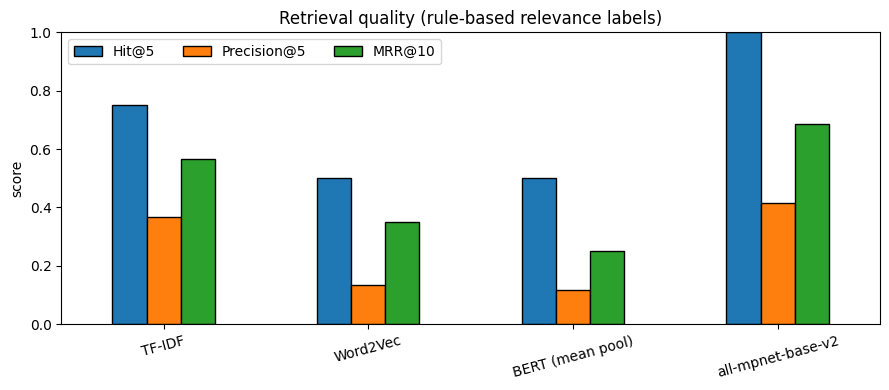

In [12]:
ax = retrieval_results.plot.bar(figsize=(9, 4), edgecolor="black", rot=15)
ax.set(ylabel="score", ylim=(0, 1), title="Retrieval quality (rule-based relevance labels)")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout()
plt.show()

### 7.2 Answer quality

All 12 questions are answered with every retriever. Three automatic signals are computed:

* **Grounding**: share of the answer's content words (stop words removed) that also appear in the retrieved passages. A low value means the model wrote something that is not in its context, a rough indicator of hallucination.
* **Term coverage**: share of a small set of expected concept groups (for example `stimulus` and `response` for classical conditioning) that appear in the answer, i.e. whether the answer touches the expected concepts. The concept lists were written once, before looking at any answers.
* **Refusal rate**: share of answers that say the answer cannot be found in the context.

Grounding rewards copying and saturates easily when an answer is extracted from the context, so it must be read together with term coverage: a good answer is both grounded and on-topic.

In [13]:
REFUSAL = re.compile(r"cannot find|can't find|not (?:in|present in|found in) the context|unable to find", re.I)


def content_words(text: str) -> List[str]:
    return [w for w in re.findall(r"[a-z]+", text.lower()) if w not in STOPWORDS and len(w) > 2]


def grounding(answer: str, contexts: List[str]) -> float:
    words = content_words(answer)
    if not words:
        return float("nan")
    ctx_vocab = set(content_words(" ".join(contexts)))
    return float(np.mean([w in ctx_vocab for w in words]))


def term_coverage(answer: str, groups: List[str]) -> float:
    """Share of the concept groups (regex alternations) that appear in the answer."""
    return float(np.mean([bool(re.search(g, answer.lower())) for g in groups]))


def evaluate_generation() -> pd.DataFrame:
    rows = []
    for item in tqdm(EVAL_SET, desc="Generating answers"):
        for method in retrievers:
            res = rag_answer(item["question"], method)
            rows.append({
                "question": item["question"], "method": method, "answer": res["answer"],
                "pages": res["pages"], "prompt_tokens": res["prompt_tokens"],
                "grounding": grounding(res["answer"], res["contexts"]),
                "term_coverage": term_coverage(res["answer"], item["answer_terms"]),
                "refusal": bool(REFUSAL.search(res["answer"])),
            })
    return pd.DataFrame(rows)


generation_df = evaluate_generation()
assert generation_df["prompt_tokens"].max() <= LLM_MAX_INPUT_TOKENS, "prompt exceeded the token limit"

generation_results = generation_df.groupby("method", sort=False).agg(
    grounding=("grounding", "mean"), term_coverage=("term_coverage", "mean"),
    refusal_rate=("refusal", "mean"), avg_answer_words=("answer", lambda s: s.str.split().str.len().mean()),
)
generation_results

Generating answers:   0%|          | 0/12 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (758 > 512). Running this sequence through the model will result in indexing errors


,grounding,term_coverage,refusal_rate,avg_answer_words
method,,,,
TF-IDF,1.000000,0.541667,0.000000,11.416667
Word2Vec,1.000000,0.416667,0.000000,11.000000
BERT (mean pool),0.825298,0.416667,0.083333,13.083333
all-mpnet-base-v2,1.000000,0.625000,0.000000,12.000000


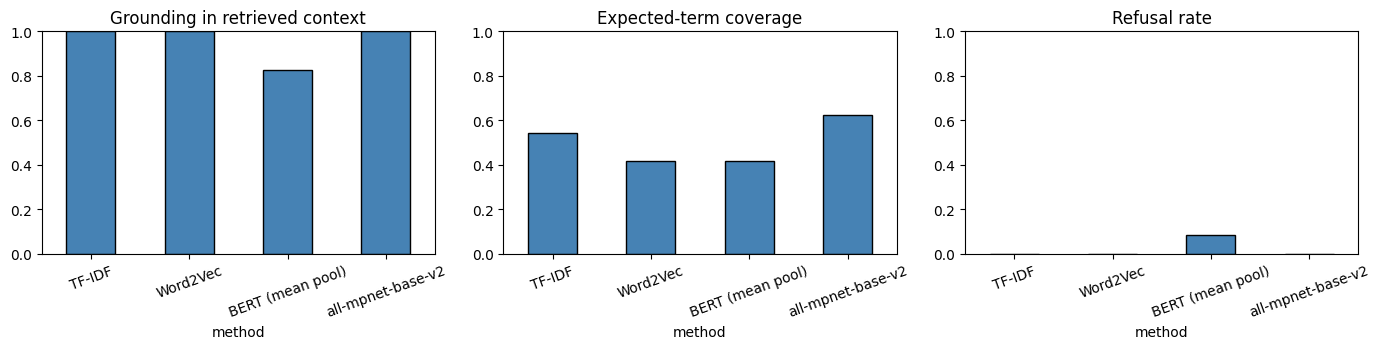

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col, title in zip(axes, ["grounding", "term_coverage", "refusal_rate"],
                          ["Grounding in retrieved context", "Expected-term coverage", "Refusal rate"]):
    generation_results[col].plot.bar(ax=ax, color="steelblue", edgecolor="black", rot=20)
    ax.set(title=title, ylim=(0, 1))
plt.tight_layout()
plt.show()

### 7.3 Manual spot-check

Automatic scores are proxies, so a few answers should always be read directly. The table shows the answers for two questions side by side.

In [15]:
pd.set_option("display.max_colwidth", 260)
spot = generation_df[generation_df["question"].isin([EVAL_SET[1]["question"], EVAL_SET[7]["question"]])]
spot.pivot(index="question", columns="method", values="answer")[list(retrievers)].T

question,How does classical conditioning work?,What are Piaget's stages of cognitive development?
method,,
TF-IDF,"In classical conditioning, organisms learn to associate events that repeatedly happen together","formal operational thought, which develops between 11 and 20 years old"
Word2Vec,"In classical conditioning, organisms learn to associate events that repeatedly happen together",explains how children think and reason as they move through various stages
BERT (mean pool),not enough information to answer the above question 'How does the human brain work?,unanswerable if not stated in the text.
all-mpnet-base-v2,"the initial period of learning is known as acquisition, when an organism learns to connect a neutral stimulus and an unconditioned stimulus","formal operational thought, which develops between 11 and 20 years old"


## 8. Try it yourself

In [16]:
ask("What is the difference between short-term memory and long-term memory?")
ask("How does stress affect the immune system?", method="TF-IDF")

Q: What is the difference between short-term memory and long-term memory?
A (all-mpnet-base-v2): Long-term memory (LTM) is the continuous storage of information
Sources: pages [263, 263, 265]
Q: How does stress affect the immune system?
A (TF-IDF): inhibiting the production of lymphocytes, white blood cells that circulate in the body’s fluids that are important in the immune response
Sources: pages [515, 513, 514]


## 9. Design decisions and limitations

**Choices that matter**

* *Full-corpus parsing with page-bounded, sentence-based chunks*: keeps passages coherent and every answer traceable to a page.
* *Boilerplate filter*: removes tables of contents, figure captions and reference fragments that otherwise match queries by accident.
* *L2 normalisation and cosine similarity for every method*: no retriever benefits from a different distance.
* *Token-budgeted prompt*: the question and instruction are never truncated, and each passage gets an equal share of the context window.
* *Same LLM, same prompt, same `k` for every retriever*: the retriever is the only variable.

**Limitations**

* Relevance labels are keyword rules (see section 7), which favour lexical matching. A human-labelled or LLM-judged set would be a stronger benchmark.
* BERT is used without any retrieval fine-tuning, so its embeddings are not expected to be competitive with a model trained for semantic search.
* Flan-T5-base is small and its answers are short; it can copy a sentence instead of synthesising one. A larger generator (`flan-t5-large`, or an instruction-tuned decoder model) would raise answer quality without changing the retrieval comparison.
* Retrieval is single-stage. A cross-encoder re-ranker and hybrid lexical + dense scoring are the obvious next steps.
* Results come from one textbook and one question set; the ranking of methods may differ on other corpora.